In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib
import os

import testis_model as tm

In [2]:
from analysis import small_label_settings
plt.style.use('default')
plt.rcParams.update(small_label_settings)

In [3]:
sample_times = [tm.data_processing.sample_map_int[t] for t in np.arange(1,16)]

In [4]:
params = dict(
    n_stem = 1000,
    n_clones = 10,
    r_event = 36,
    p_diff = 0,
    r_decay = 0,
    sperm_per_diff = 1300,
    tau = 0.2
)

rng = np.random.default_rng(3)

init_freq = tm.gillespie.sample_ic(params['n_stem'], params['n_clones'], rng)
hmm = tm.gillespie.AdvancedTestisModel(**params, init_freq = init_freq)

n_sperm = 500

samples1, _, _ = hmm.simulate_gillespie(sample_times, n_sperm = n_sperm, rng = rng, init_time = 4)
tm.data_processing.sort_results(samples1);

In [5]:
params = dict(
    n_stem = 1000,
    n_clones = 10,
    r_event = 36,
    p_diff = 2 / 36,
    r_decay = 0,
    sperm_per_diff = 1300,
    tau = 0.2
)
rng = np.random.default_rng(4)

init_freq = tm.gillespie.sample_ic(params['n_stem'], params['n_clones'], rng)

hmm = tm.gillespie.AdvancedTestisModel(**params, init_freq = init_freq)

n_sperm = 500

samples2, _, _ = hmm.simulate_gillespie(sample_times, n_sperm = n_sperm, rng = rng, init_time = 4)
tm.data_processing.sort_results(samples2);

In [6]:
params = dict(
    n_stem = 1000,
    n_clones = 10,
    r_event = 36,
    p_diff = 8 / 36,
    r_decay = 0,
    sperm_per_diff = 1300,
    tau = 0.2
)

rng = np.random.default_rng(5)

init_freq = tm.gillespie.sample_ic(params['n_stem'], params['n_clones'], rng)

hmm = tm.gillespie.AdvancedTestisModel(**params, init_freq = init_freq)

n_sperm = 500

samples3, _, _ = hmm.simulate_gillespie(sample_times, n_sperm = n_sperm, rng = rng, init_time = 4)
tm.data_processing.sort_results(samples3);

In [16]:
params = dict(
    n_stem = 1000,
    n_clones = 10,
    r_event = 36,
    p_diff = 25 / 36,
    r_decay = 0,
    sperm_per_diff = 1300,
    tau = 0.2
)

rng = np.random.default_rng(6)

init_freq = tm.gillespie.sample_ic(params['n_stem'], params['n_clones'], rng)

hmm = tm.gillespie.AdvancedTestisModel(**params, init_freq = init_freq)

n_sperm = 500

samples4, _, _ = hmm.simulate_gillespie(sample_times, n_sperm = n_sperm, rng = rng, init_time = 4)
tm.data_processing.sort_results(samples4);

In [17]:
# fig, ax = plt.subplots(1, 3, figsize = (3.5, 1.2), dpi = 300)
# tm.visualize.plot(samples1, ax = ax[0]);
# ax[0].set_title('No drift\n(' + r'$ \it{rp} $' + ' = 0)')
# ax[0].set_xlabel('')
# ax[0].set_xticks(sample_times)
# ax[0].set_xticklabels([])   
# ax[0].set_yticks([])
# ax[0].set_ylabel('Barcode frequency', fontweight = 'bold')

# tm.visualize.plot(samples2, ax = ax[1]);
# # ax[1].set_title('Moderate drift\n(rp = 2)')
# ax[1].set_title('Moderate drift\n(' + r'$ \it{rp} $' + ' = 2)')
# ax[1].set_xlabel('')
# ax[1].set_ylabel('')
# ax[1].set_xticks(sample_times)
# ax[1].set_xticklabels([])           
# ax[1].set_yticks([])

# tm.visualize.plot(samples3, ax = ax[2]);
# ax[2].set_title('Strong drift\n(' + r'$ \it{rp} $' + ' = 8)')
# ax[2].set_xlabel('')
# ax[2].set_ylabel('')
# ax[2].set_xticks(sample_times)
# ax[2].set_xticklabels([])   
# ax[2].set_yticks([])

# fig.supxlabel("Age (months)", y=0, fontweight = 'bold', fontsize = 7)

# fig.tight_layout(pad=0.5)
# fig.savefig('images/fig3/sample_simulations.svg', bbox_inches = 'tight', pad_inches = 0)
# fig.savefig('images/fig3/sample_simulations.png', dpi = 300, bbox_inches = 'tight', pad_inches = 0)

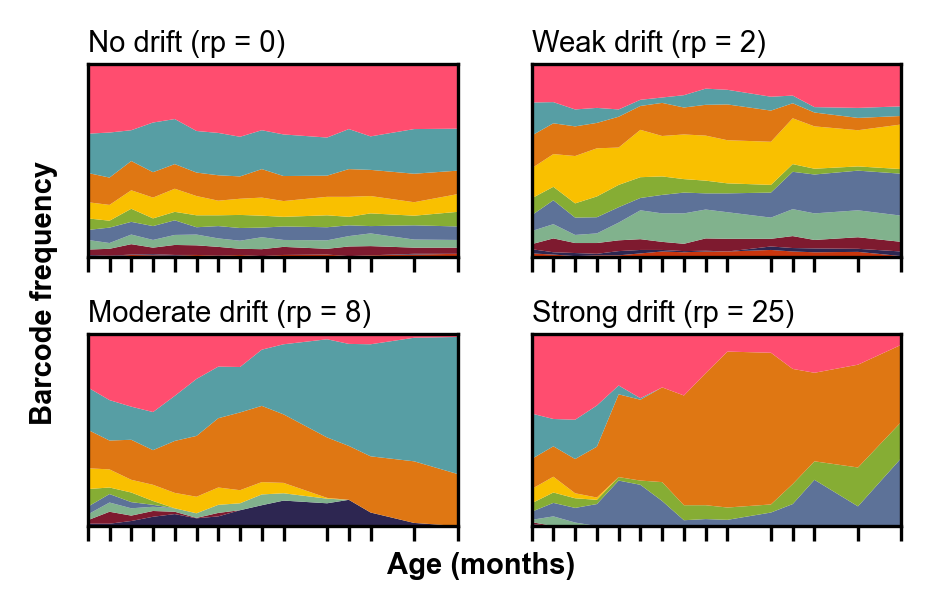

In [18]:
fig, ax = plt.subplots(2, 2, figsize = (3.5, 2), dpi = 300)
plt.subplots_adjust(hspace=0.4)
tm.visualize.plot(samples1, ax = ax[0,0]);
ax[0,0].set_title('No drift (rp = 0)', loc = 'left', pad = 3)
ax[0,0].set_xlabel('')
ax[0,0].set_xticks(sample_times)
ax[0,0].set_xticklabels([])   
ax[0,0].set_yticks([])
ax[0,0].set_ylabel('')

tm.visualize.plot(samples2, ax = ax[0,1]);
# ax[0,1].set_title('Moderate drift\n(rp = 2)')
ax[0,1].set_title('Weak drift (rp = 2)', loc = 'left', pad = 3)
ax[0,1].set_xlabel('')
ax[0,1].set_ylabel('')
ax[0,1].set_xticks(sample_times)
ax[0,1].set_xticklabels([])           
ax[0,1].set_yticks([])

tm.visualize.plot(samples3, ax = ax[1,0]);
ax[1,0].set_title('Moderate drift (rp = 8)', loc = 'left', pad = 3)
ax[1,0].set_xlabel('')
ax[1,0].set_ylabel('')
ax[1,0].set_xticks(sample_times)
ax[1,0].set_xticklabels([])   
ax[1,0].set_yticks([])

tm.visualize.plot(samples4, ax = ax[1,1]);
ax[1,1].set_title('Strong drift (rp = 25)', loc = 'left', pad = 3)
ax[1,1].set_xlabel('')
ax[1,1].set_ylabel('')
ax[1,1].set_xticks(sample_times)
ax[1,1].set_xticklabels([])   
ax[1,1].set_yticks([])

fig.supxlabel("Age (months)", y=0.02, fontweight = 'bold', fontsize = 7)
fig.supylabel("Barcode frequency", fontweight = 'bold', fontsize = 7, x = 0.07)

# fig.tight_layout(pad=0.5)
fig.savefig('images/fig3/sample_simulations.svg', bbox_inches = 'tight', pad_inches = 0)
fig.savefig('images/fig3/sample_simulations.png', dpi = 300, bbox_inches = 'tight', pad_inches = 0)